<a href="https://colab.research.google.com/github/zeemohamed7/ai-traffic-project/blob/main/IT7009_Traffic_Incident_FeatureAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Data Exploration and Preprocessing

## 1.1 Initial Dataset Exploration

In [ ]:
# Load dataset
import pandas as pd


dataset_url = "https://raw.githubusercontent.com/zeemohamed7/ai-traffic-project/main/Dataset_Brief_1.xlsx"

df = pd.read_excel(dataset_url)

df.head()

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [ ]:
# Check the dataset size
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five records
display(df.head())

# Display column names and data types
df.info()


Dataset shape: (50010, 72)
Number of rows: 50010
Number of columns: 72


,Incident_ID,Start_Time,End_Time,Severity,Incident_Type,State,City,District,Latitude,Longitude,...,Day,Month,Year,Weekday,Weekend,Peak_Hour,Season,Travel_Time_Minutes,Travel_Category,Risk_Score
0,8691.0,2/3/2022 15:14,2/3/2022 15:49,4.0,Vehicle Breakdown,Westland,Gamma Town,District-8,35.672669,-101.278196,...,3.0,2.0,2022.0,Thursday,0.0,0.0,Winter,35.0,Medium,137.2
1,446494.0,8/14/2020 8:11,8/14/2020 13:40,3.0,Overturned Vehicle,Southland,Epsilon,District-4,24.231835,-98.252526,...,14.0,8.0,2020.0,Friday,0.0,1.0,Summer,329.0,Long,85.6
2,123320.0,8/26/2023 9:36,8/26/2023 14:48,1.0,Multi Vehicle,Coastland,Stonebridge,District-21,37.063287,-93.811779,...,26.0,8.0,2023.0,Saturday,1.0,1.0,Summer,312.0,Long,44.8
3,331693.0,11/25/2023 7:17,11/25/2023 9:52,3.0,Road Block,Midland,Alpha City,District-17,39.836266,-105.004800,...,25.0,11.0,2023.0,Saturday,1.0,1.0,Autumn,155.0,Long,106
4,215089.0,3/14/2022 4:28,3/14/2022 5:11,4.0,Overturned Vehicle,Highland,Springfield,District-20,40.111869,-96.192756,...,14.0,3.0,2022.0,Monday,0.0,0.0,Spring,43.0,Medium,149.6


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50010 entries, 0 to 50009
Data columns (total 72 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Incident_ID               50005 non-null  float64
 1   Start_Time                50004 non-null  object 
 2   End_Time                  50004 non-null  object 
 3   Severity                  50003 non-null  float64
 4   Incident_Type             50004 non-null  object 
 5   State                     50004 non-null  object 
 6   City                      50004 non-null  object 
 7   District                  50004 non-null  object 
 8   Latitude                  50004 non-null  float64
 9   Longitude                 50004 non-null  float64
 10  Postal_Code               50004 non-null  object 
 11  Road_Name                 50004 non-null  object 
 12  Road_Type                 50004 non-null  object 
 13  Road_Surface              50004 non-null  object 
 14  Weathe

In [ ]:
# Count missing values
print("Missing values:")
print(df.isnull().sum().sort_values(ascending=False))

# Count duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Get numerical statistics
display(df.describe())


Missing values:
Severity         7
Humidity         7
Risk_Score       7
Start_Time       6
City             6
                ..
Nearby_School    5
Turning_Loop     5
Month            5
Peak_Hour        5
Year             5
Length: 72, dtype: int64

Duplicate records: 14


,Incident_ID,Severity,Latitude,Longitude,Humidity,Pressure,Visibility,Wind_Speed,Precipitation,Cloud_Cover,...,Speed_Camera,Congestion_Index,Accident_History,Hour,Day,Month,Year,Weekend,Peak_Hour,Travel_Time_Minutes
count,50005.000000,50003.000000,50004.000000,50004.000000,50003.000000,50004.000000,50004.000000,50005.000000,50004.000000,50004.000000,...,50005.000000,50004.000000,50004.000000,50004.000000,50004.000000,50005.000000,50005.000000,50004.000000,50005.000000,50004.000000
mean,250911.870413,3.450773,37.519081,-95.050219,59.983281,1007.534025,5.258971,29.943172,3.549928,49.964803,...,0.497650,50.593593,9.894068,11.513619,15.740001,6.499530,2021.494151,0.286117,0.251395,182.647728
std,144274.116165,0.693349,10.095004,14.417630,23.351561,15.885841,2.737345,17.316189,3.249110,29.187602,...,0.499999,28.871691,6.080011,6.920104,8.778496,3.448158,1.122110,0.451949,0.433819,102.586078
min,13.000000,1.000000,20.000805,-200.000000,-10.000000,980.000000,-5.000000,0.000000,-3.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,2020.000000,0.000000,0.000000,5.000000
25%,126381.000000,3.000000,28.828846,-107.472258,40.000000,993.800000,2.900000,15.000000,0.300000,25.000000,...,0.000000,26.000000,5.000000,6.000000,8.000000,4.000000,2020.000000,0.000000,0.000000,94.000000
50%,250441.000000,4.000000,37.483440,-95.134850,60.000000,1007.700000,5.200000,29.900000,3.000000,50.000000,...,0.000000,51.000000,10.000000,12.000000,16.000000,7.000000,2021.000000,0.000000,0.000000,183.000000
75%,375351.000000,4.000000,46.256761,-82.603417,80.000000,1021.300000,7.600000,44.900000,5.700000,75.000000,...,1.000000,76.000000,15.000000,18.000000,23.000000,9.000000,2023.000000,1.000000,1.000000,272.000000
max,499999.000000,4.000000,95.000000,-70.000152,150.000000,1035.000000,10.000000,60.000000,18.500000,100.000000,...,1.000000,100.000000,20.000000,23.000000,31.000000,12.000000,2023.000000,1.000000,1.000000,360.000000


## 1.2 Data Quality Assessment

### 1.2.1 Missing Value Analysis
This type of analysis looks at how missing values are spread out throughout the records of the data set. The results will help determine an appropriate strategy for handling missing values during *preprocessing*.

In [ ]:

# Calculate missing values for each record
missing_counts = df.isna().sum(axis=1)

# Summarize the distribution of missing values
summary = pd.DataFrame({
    "Missing Values": ["None", "1", "2", "3", "Entire Row"],
    "Number of Records": [
        (missing_counts == 0).sum(),
        (missing_counts == 1).sum(),
        (missing_counts == 2).sum(),
        (missing_counts == 3).sum(),
        (missing_counts == df.shape[1]).sum()
    ]
})

# Calculate percentages
summary["Percentage (%)"] = (
    summary["Number of Records"] / len(df) * 100
).round(3)

display(summary)


,Missing Values,Number of Records,Percentage (%)
0,None,49979,99.938
1,1,8,0.016
2,2,14,0.028
3,3,4,0.008
4,Entire Row,5,0.010


**Observation:** Approximately 99.94% of the dataset records are complete. Five records are entirely empty, while 26 contain between one and three missing values. The completely empty records will be removed during preprocessing, and the remaining incomplete records will be investigated before selecting a treatment method.

### 1.2.2 Handling Missing Values
Completely empty records are removed because they contain no usable information. The original dataset is preserved, while subsequent cleaning operations are performed on a separate copy.*italicised text*

In [ ]:
# Preserve the original dataset
df_clean = df.copy()

# Remove records with no available information
df_clean = df_clean.dropna(how="all")

# Verify the cleaning operation
print(f"Original records: {len(df):,}")
print(f"Remaining records: {len(df_clean):,}")
print(f"Records removed: {len(df) - len(df_clean):,}")


Original records: 50,010
Remaining records: 50,005
Records removed: 5


In [ ]:
# Show remaining missing values by column
df_clean.isnull().sum().loc[lambda x: x > 0]

,0
Start_Time,1
End_Time,1
Severity,2
Incident_Type,1
State,1
City,1
District,1
Latitude,1
Longitude,1
Postal_Code,1


In [ ]:

# Remove records containing any remaining missing values
rows_before = len(df_clean)

df_clean = df_clean.dropna().copy()

# Verify the results
print(f"Records before: {rows_before:,}")
print(f"Records after: {len(df_clean):,}")
print(f"Records removed: {rows_before - len(df_clean):,}")
print(f"Missing values remaining: {df_clean.isna().sum().sum()}")


Records before: 50,005
Records after: 49,979
Records removed: 26
Missing values remaining: 0


### 1.2.3 Duplicate Records
Duplicate records were examined to identify repeated observations that could affect the reliability of the analysis and introduce bias during model training.

In [ ]:
# Count duplicate records
duplicates = df_clean.duplicated().sum()

print(f"Total duplicate records: {duplicates}")

# Display duplicate records
display(df_clean[df_clean.duplicated(keep=False)].head(10))


Total duplicate records: 10


,Incident_ID,Start_Time,End_Time,Severity,Incident_Type,State,City,District,Latitude,Longitude,...,Day,Month,Year,Weekday,Weekend,Peak_Hour,Season,Travel_Time_Minutes,Travel_Category,Risk_Score
99,351626.0,11/12/2022 13:19,11/12/2022 16:45,4.0,Overturned Vehicle,Westland,Epsilon,District-8,21.207160,-75.990215,...,12.0,11.0,2022.0,Saturday,1.0,0.0,Autumn,206.0,Long,180.8
100,79897.0,2/4/2023 23:44,2/5/2023 1:56,3.0,Road Block,Westland,Greenfield,District-9,45.538702,-109.596262,...,4.0,2.0,2023.0,Saturday,1.0,0.0,Winter,132.0,Long,114.4
101,136080.0,7/3/2022 9:03,7/3/2022 11:34,4.0,Overturned Vehicle,Greenville,Alpha City,District-10,35.150339,-75.794321,...,3.0,7.0,2022.0,Sunday,1.0,1.0,Summer,151.0,Long,158.4
102,339658.0,9/3/2020 0:49,9/3/2020 2:07,4.0,Multi Vehicle,Midland,Omega,District-10,41.617292,-117.546538,...,3.0,9.0,2020.0,Thursday,0.0,0.0,Autumn,78.0,Medium,112.8
103,195369.0,7/11/2023 18:50,7/11/2023 23:20,4.0,Collision,Lakeland,Gamma Town,District-9,24.285474,-102.784821,...,11.0,7.0,2023.0,Tuesday,0.0,1.0,Summer,270.0,Long,148.4
104,417216.0,7/20/2022 22:27,7/20/2022 22:43,4.0,Road Block,Coastland,Clearwater,District-2,39.754010,-94.596067,...,20.0,7.0,2022.0,Wednesday,0.0,0.0,Summer,16.0,Short,135.2
105,207578.0,10/30/2021 5:54,10/30/2021 11:48,4.0,Pedestrian,Greenville,Beta City,District-17,37.233600,-102.570903,...,30.0,10.0,2021.0,Saturday,1.0,0.0,Autumn,354.0,Long,156.4
106,380015.0,4/14/2021 2:20,4/14/2021 7:04,4.0,Multi Vehicle,Westland,Clearwater,District-20,52.416452,-104.813348,...,14.0,4.0,2021.0,Wednesday,0.0,0.0,Spring,284.0,Long,143.6
107,356900.0,8/4/2022 5:10,8/4/2022 9:19,3.0,Road Block,Highland,Greenfield,District-4,44.891309,-75.882372,...,4.0,8.0,2022.0,Thursday,0.0,0.0,Summer,249.0,Long,104.4
108,387509.0,9/3/2022 23:47,9/4/2022 5:12,4.0,Overturned Vehicle,Northland,Alpha City,District-22,41.520143,-83.638840,...,3.0,9.0,2022.0,Saturday,1.0,0.0,Autumn,325.0,Long,165.6


In [ ]:

# Remove duplicate records
rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

# Verify the result
print(f"Records before: {rows_before:,}")
print(f"Records after: {len(df_clean):,}")
print(f"Duplicates removed: {rows_before - len(df_clean):,}")
print(f"Remaining duplicates: {df_clean.duplicated().sum()}")


Records before: 49,979
Records after: 49,969
Duplicates removed: 10
Remaining duplicates: 0


### 1.2.4 Data Type Validation

The data types of all columns were examined to identify attributes stored in incorrect formats. Numerical, categorical, and temporal attributes were reviewed before applying any conversions.**bold text**

In [ ]:
# Display every column and its data type
data_types = pd.DataFrame({
    "Column": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values
})

display(data_types)

,Column,Data Type
0,Incident_ID,float64
1,Start_Time,object
2,End_Time,object
3,Severity,float64
4,Incident_Type,object
...,...,...
67,Peak_Hour,float64
68,Season,object
69,Travel_Time_Minutes,float64
70,Travel_Category,object


In [ ]:

# Numerical columns stored as text
numeric_columns = [
    "Temperature",
    "Average_Speed",
    "Vehicle_Count",
    "Emergency_Response_Time",
    "Road_Width",
    "Risk_Score"
]

# Check for values that cannot be converted to numbers
for col in numeric_columns:
    converted = pd.to_numeric(df_clean[col], errors="coerce")
    invalid = df_clean.loc[converted.isna() & df_clean[col].notna(), col]

    print(f"{col}: {len(invalid)} invalid values")

    if len(invalid) > 0:
        print("Invalid entries:", invalid.unique())


Temperature: 1 invalid values
Invalid entries: ['unknown']
Average_Speed: 1 invalid values
Invalid entries: ['fifty']
Vehicle_Count: 1 invalid values
Invalid entries: ['12 vehicles']
Emergency_Response_Time: 1 invalid values
Invalid entries: ['pending']
Road_Width: 1 invalid values
Invalid entries: ['wide']
Risk_Score: 1 invalid values
Invalid entries: ['high']


In [ ]:

# Display the records containing invalid numerical values
for col in numeric_columns:
    converted = pd.to_numeric(df_clean[col], errors="coerce")
    invalid_rows = df_clean.loc[
        converted.isna() & df_clean[col].notna(),
        ["Incident_ID", col]
    ]

    if not invalid_rows.empty:
        print(f"\n{col}")
        display(invalid_rows)



Temperature


,Incident_ID,Temperature
1199,386307.0,unknown



Average_Speed


,Incident_ID,Average_Speed
3199,347227.0,fifty



Vehicle_Count


...

,Incident_ID,Emergency_Response_Time
6199,117282.0,pending



Road_Width


,Incident_ID,Road_Width
5199,153250.0,wide



Risk_Score


,Incident_ID,Risk_Score
8199,466098.0,high


In [ ]:
# Correct values with clear numerical meanings
df_clean["Average_Speed"] = df_clean["Average_Speed"].astype(str).replace("fifty", "50")
df_clean["Vehicle_Count"] = df_clean["Vehicle_Count"].astype(str).replace("12 vehicles", "12")

# Convert all six columns to numerical types
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Verify data types and missing values
display(df_clean[numeric_columns].dtypes)

print("\nMissing values after conversion:")
print(df_clean[numeric_columns].isna().sum())

,0
Temperature,float64
Average_Speed,int64
Vehicle_Count,int64
Emergency_Response_Time,float64
Road_Width,float64
Risk_Score,float64



Missing values after conversion:
Temperature                1
Average_Speed              0
Vehicle_Count              0
Emergency_Response_Time    1
Road_Width                 1
Risk_Score                 1
dtype: int64


In [ ]:
# Remove records containing invalid numerical values
rows_before = len(df_clean)

df_clean = df_clean.dropna().copy()

print(f"Records removed: {rows_before - len(df_clean)}")
print(f"Remaining records: {len(df_clean):,}")
print(f"Missing values remaining: {df_clean.isna().sum().sum()}")

Records removed: 4
Remaining records: 49,965
Missing values remaining: 0


In [ ]:
# Integer validation
# Define columns that should contain whole numbers
integer_columns = [
    "Incident_ID", "Severity",
    "Vehicle_Count", "Pedestrian_Count",
    "Bicycle_Count", "Lane_Count",
    "Accident_History",
    "Hour", "Day", "Month", "Year"
]

# Check each column for fractional values
for col in integer_columns:
    invalid_count = (df_clean[col] % 1 != 0).sum()

    print(f"{col}: {invalid_count} non-integer values")

Incident_ID: 0 non-integer values
Severity: 0 non-integer values
Vehicle_Count: 0 non-integer values
Pedestrian_Count: 0 non-integer values
Bicycle_Count: 0 non-integer values
Lane_Count: 0 non-integer values
Accident_History: 0 non-integer values
Hour: 0 non-integer values
Day: 0 non-integer values
Month: 0 non-integer values
Year: 0 non-integer values


In [ ]:
# Columns expected to contain only 0 or 1
binary_columns = [
    "Traffic_Signal", "Junction", "Railway", "Crossing",
    "Stop_Sign", "Roundabout", "Amenity", "Station",
    "Bump", "Turning_Loop", "Give_Way", "No_Exit",
    "Nearby_School", "Nearby_Hospital", "Nearby_Market",
    "Nearby_Airport", "Nearby_Bus_Station", "Road_Work",
    "Holiday", "Camera_Available", "Sensor_Available",
    "Speed_Camera", "Weekend", "Peak_Hour"
]

# Check for values other than 0 and 1
for col in binary_columns:
    invalid_count = (~df_clean[col].isin([0, 1])).sum()
    print(f"{col}: {invalid_count} invalid values")

Traffic_Signal: 0 invalid values
Junction: 0 invalid values
Railway: 0 invalid values
Crossing: 0 invalid values
Stop_Sign: 0 invalid values
Roundabout: 0 invalid values
Amenity: 0 invalid values
Station: 0 invalid values
Bump: 0 invalid values
Turning_Loop: 0 invalid values
Give_Way: 0 invalid values
No_Exit: 0 invalid values
Nearby_School: 0 invalid values
Nearby_Hospital: 0 invalid values
Nearby_Market: 0 invalid values
Nearby_Airport: 0 invalid values
Nearby_Bus_Station: 0 invalid values
Road_Work: 0 invalid values
Holiday: 0 invalid values
Camera_Available: 0 invalid values
Sensor_Available: 0 invalid values
Speed_Camera: 0 invalid values
Weekend: 0 invalid values
Peak_Hour: 0 invalid values


In [ ]:
# Date validation
# Convert timestamps to datetime without changing the dataset yet
start_time = pd.to_datetime(df_clean["Start_Time"], errors="coerce")
end_time = pd.to_datetime(df_clean["End_Time"], errors="coerce")

# Check for invalid dates and incorrect chronological order
print("Invalid Start_Time:", start_time.isna().sum())
print("Invalid End_Time:", end_time.isna().sum())
print("End_Time before Start_Time:", (end_time < start_time).sum())

# Display examples of the converted timestamps
display(pd.DataFrame({
    "Start_Time": start_time.head(),
    "End_Time": end_time.head()
}))

Invalid Start_Time: 3
Invalid End_Time: 3
End_Time before Start_Time: 0


,Start_Time,End_Time
0,2022-02-03 15:14:00,2022-02-03 15:49:00
1,2020-08-14 08:11:00,2020-08-14 13:40:00
2,2023-08-26 09:36:00,2023-08-26 14:48:00
3,2023-11-25 07:17:00,2023-11-25 09:52:00
4,2022-03-14 04:28:00,2022-03-14 05:11:00


In [ ]:
# Find records with invalid start or end timestamps
invalid_dates = df_clean[
    start_time.isna() | end_time.isna()
]

# Display the original values for inspection
display(invalid_dates[
    ["Incident_ID", "Start_Time", "End_Time",
     "Year", "Month", "Day", "Hour"]
])

print("Total affected records:", len(invalid_dates))

,Incident_ID,Start_Time,End_Time,Year,Month,Day,Hour
899,322894.0,invalid date,7/24/2020 11:31,2020.0,7.0,24.0,9.0
1899,33895.0,11/7/2023 17:23,not recorded,2023.0,11.0,7.0,17.0
2899,461817.0,2025-13-40 25:61:00,1/20/2020 19:28,2020.0,1.0,20.0,16.0
3899,7050.0,2/13/2023 5:35,01/02/25,2023.0,2.0,13.0,5.0
4899,222298.0,"March 5th, 2025",3/23/2021 7:35,2021.0,3.0,23.0,4.0
5899,279636.0,2/10/2021 15:22,2024/99/99,2021.0,2.0,10.0,15.0


Total affected records: 6


In [ ]:
# Remove records with unreliable timestamps
rows_before = len(df_clean)

df_clean = df_clean.drop(index=invalid_dates.index).copy()

print("Records removed:", rows_before - len(df_clean))
print("Remaining records:", len(df_clean))

Records removed: 6
Remaining records: 49959


In [ ]:
# Convert timestamp columns to datetime
df_clean["Start_Time"] = pd.to_datetime(df_clean["Start_Time"], errors="coerce")
df_clean["End_Time"] = pd.to_datetime(df_clean["End_Time"], errors="coerce")

# Verify the conversions
print(df_clean[["Start_Time", "End_Time"]].dtypes)
print("Invalid timestamps:", df_clean[["Start_Time", "End_Time"]].isna().sum().sum())
print("End before start:", (df_clean["End_Time"] < df_clean["Start_Time"]).sum())

Start_Time    datetime64[ns]
End_Time      datetime64[ns]
dtype: object
Invalid timestamps: 0
End before start: 0


In [ ]:
# Convert timestamps to datetime
df_clean["Start_Time"] = pd.to_datetime(df_clean["Start_Time"], errors="coerce")
df_clean["End_Time"] = pd.to_datetime(df_clean["End_Time"], errors="coerce")

# Check for invalid timestamps or incorrect chronological order
print("Invalid timestamps:",
      df_clean[["Start_Time", "End_Time"]].isna().sum().sum())

print("End before start:",
      (df_clean["End_Time"] < df_clean["Start_Time"]).sum())

# Check that recorded date components match Start_Time
for col, component in {
    "Year": df_clean["Start_Time"].dt.year,
    "Month": df_clean["Start_Time"].dt.month,
    "Day": df_clean["Start_Time"].dt.day,
    "Hour": df_clean["Start_Time"].dt.hour
}.items():
    print(f"{col} mismatches:", (df_clean[col] != component).sum())

Invalid timestamps: 0
End before start: 0
Year mismatches: 0
Month mismatches: 0
Day mismatches: 0
Hour mismatches: 0


In [ ]:
# Categorical Data Validation
# Identify categorical columns, excluding timestamps
categorical_columns = df_clean.select_dtypes(include="object").columns

# Display unique values for each categorical column
for col in categorical_columns:
    print(f"\n{col} ({df_clean[col].nunique()} unique values)")
    print(df_clean[col].value_counts().to_string())

Streaming output truncated to the last 5000 lines.
Shelton Row                1
Jones Rapid                1
Woods Crossroad            1
Butler Valleys             1
Jennifer Trace             1
Haley Fields               1
Austin Pine                1
Jaime Key                  1
Melton Cliff               1
Garcia Cliffs              1
Serrano Falls              1
Estrada Plaza              1
Victor Springs             1
Woodard Valley             1
Avery Forks                1
Austin Keys                1
Scott Corner               1
Holden Mills               1
Dunn Knolls                1
Bailey Circle              1
Tiffany Light              1
Madden Gateway             1
Davis Valley               1
Connie Prairie             1
Roy Place                  1
Jimmy Club                 1
Jamie Mills                1
Hall Lake                  1
Patrick Fort               1
Latasha Junction           1
Mendoza Tunnel             1
Sabrina Hills              1
Myers Harbor         

In [ ]:
# Remove extra spaces and standardize capitalization
columns_to_standardize = [
    "Road_Surface", "Weather_Condition",
    "Vehicle_Type", "Response_Team", "Weekday"
]

for col in columns_to_standardize:
    df_clean[col] = df_clean[col].str.strip().str.title()

# Correct specific labels
df_clean["Light_Condition"] = (
    df_clean["Light_Condition"].str.strip()
    .replace("day light", "Daylight")
)

df_clean["Weekday"] = df_clean["Weekday"].replace("Fri", "Friday")

# Check the results
for col in columns_to_standardize + ["Light_Condition"]:
    print("\n" + col)
    print(df_clean[col].value_counts())


Road_Surface
Road_Surface
Wet     12544
Dry     12507
Snow    12471
Ice     12437
Name: count, dtype: int64

Weather_Condition
Weather_Condition
Clear     7325
Windy     7225
Cloudy    7163
Storm     7114
Rain      7047
Fog       7045
Snow      7040
Name: count, dtype: int64

Vehicle_Type
Vehicle_Type
Car           8515
Motorcycle    8321
Bus           8307
Truck         8295
Bicycle       8278
Van           8243
Name: count, dtype: int64

Response_Team
Response_Team
Fire         12575
Mixed        12552
Ambulance    12521
Police       12311
Name: count, dtype: int64

Weekday
Weekday
Wednesday    7247
Saturday     7237
Friday       7214
Thursday     7166
Monday       7065
Sunday       7052
Tuesday      6978
Name: count, dtype: int64

Light_Condition
Light_Condition
Dawn        12624
Night       12457
Daylight    12441
Dusk        12437
Name: count, dtype: int64


In [ ]:
# Checking Incident_Type
print(df_clean["Incident_Type"].value_counts().to_string())

# Standardize incident labels
df_clean["Incident_Type"] = df_clean["Incident_Type"].str.strip().str.title()

print(df_clean["Incident_Type"].value_counts())

Incident_Type
Collision             7242
Pedestrian            7207
Multi Vehicle         7175
Overturned Vehicle    7111
Vehicle Breakdown     7102
Animal Crossing       7082
Road Block            7039
collision                1
Incident_Type
Collision             7243
Pedestrian            7207
Multi Vehicle         7175
Overturned Vehicle    7111
Vehicle Breakdown     7102
Animal Crossing       7082
Road Block            7039
Name: count, dtype: int64


In [ ]:
# Check for State, City and District labels

for col in ["State", "City", "District"]:
    print("\n" + col)
    print(df_clean[col].value_counts().to_string())


State
State
Riverland     3423
Lakeland      3385
Hillshire     3382
Coastland     3366
Northland     3364
Southland     3348
Sunstate      3338
Central       3333
Westland      3327
Greenville    3325
Midland       3318
Eastland      3295
Highland      3266
Oakshire      3262
Lowland       3227

City
City
Hillview       3442
Springfield    3394
Gamma Town     3384
Greenfield     3383
Delta City     3364
Clearwater     3346
Omega          3337
Epsilon        3325
Alpha City     3320
Beta City      3316
Nova           3291
Brookfield     3280
Zeta           3279
Metroville     3251
Stonebridge    3247

District
District
District-8     1737
District-10    1721
District-4     1716
District-19    1712
District-17    1705
District-7     1698
District-23    1695
District-16    1691
District-13    1682
District-15    1681
District-30    1680
District-11    1679
District-29    1675
District-5     1666
District-3     1660
District-18    1659
District-20    1655
District-22    1653
District-12 

In [ ]:
# Check for spaces
for col in ["State", "City", "District", "Postal_Code", "Road_Name"]:
    values = df_clean[col].astype(str)
    print(col, (values != values.str.strip()).sum())

State 0
City 0
District 0
Postal_Code 0
Road_Name 0


In [ ]:
# Check whether Weekday, Weekend, and Season agree with Start_Time.
# Derive the expected date categories
dates = df_clean["Start_Time"]

expected_weekday = dates.dt.day_name()
expected_weekend = (dates.dt.weekday >= 5).astype(int)

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

expected_season = dates.dt.month.map(season_map)

# Count category mismatches
print("Weekday mismatches:", (df_clean["Weekday"] != expected_weekday).sum())
print("Weekend mismatches:", (df_clean["Weekend"] != expected_weekend).sum())
print("Season mismatches:", (df_clean["Season"] != expected_season).sum())

Weekday mismatches: 2
Weekend mismatches: 0
Season mismatches: 0


In [ ]:
# Show recorded and expected weekdays
weekday_mismatches = df_clean[
    df_clean["Weekday"] != expected_weekday
].copy()

weekday_mismatches["Expected_Weekday"] = (
    weekday_mismatches["Start_Time"].dt.day_name()
)

display(weekday_mismatches[
    ["Incident_ID", "Start_Time", "Weekday", "Expected_Weekday"]
])

,Incident_ID,Start_Time,Weekday,Expected_Weekday
8299,477634.0,2022-05-24 05:37:00,Monday,Tuesday
9299,177699.0,2021-09-15 07:53:00,Friday,Wednesday


In [ ]:
# Correct weekdays using the validated Start_Time
df_clean["Weekday"] = df_clean["Start_Time"].dt.day_name()

# Verify all temporal categories
print("Weekday mismatches:",
      (df_clean["Weekday"] != df_clean["Start_Time"].dt.day_name()).sum())

print("Remaining records:", len(df_clean))

Weekday mismatches: 0
Remaining records: 49959


#### 1.2.5 Invalid Values and Outliers

Numerical attributes were examined to identify values outside their expected ranges. This analysis focuses on detecting invalid measurements before deciding whether they should be corrected, removed, or treated as outliers.


##### Invalid Values

In [ ]:
# Select numerical columns
numeric_columns = df_clean.select_dtypes(include="number").columns

# Inspect the ranges and percentiles
numeric_summary = df_clean[numeric_columns].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T

display(numeric_summary[
    ["min", "1%", "25%", "50%", "75%", "99%", "max"]
])

,min,1%,25%,50%,75%,99%,max
Incident_ID,13.000000,4639.580000,126384.000000,250469.000000,375348.000000,495043.260000,499999.000000
Severity,1.000000,1.000000,3.000000,4.000000,4.000000,4.000000,4.000000
Latitude,20.000805,20.366444,28.827616,37.483610,46.258280,54.650508,95.000000
Longitude,-200.000000,-119.504448,-107.473288,-95.132807,-82.600529,-70.495236,-70.000152
Temperature,-80.000000,5.500000,18.600000,24.000000,29.300000,42.400000,120.000000
Humidity,-10.000000,20.000000,40.000000,60.000000,80.000000,100.000000,150.000000
Pressure,980.000000,980.600000,993.800000,1007.700000,1021.300000,1034.500000,1035.000000
Visibility,-5.000000,0.600000,2.900000,5.200000,7.600000,9.900000,10.000000
Wind_Speed,0.000000,0.600000,15.000000,29.900000,44.900000,59.400000,60.000000
Precipitation,-3.000000,0.000000,0.300000,3.000000,5.700000,12.400000,18.500000


In [ ]:
# Check for invalid numerical values
invalid_conditions = {
    "Latitude": ~df_clean["Latitude"].between(-90, 90),
    "Longitude": ~df_clean["Longitude"].between(-180, 180),
    "Humidity": ~df_clean["Humidity"].between(0, 100),
    "Visibility": df_clean["Visibility"] < 0,
    "Precipitation": df_clean["Precipitation"] < 0,
    "Average_Speed": df_clean["Average_Speed"] < 0
}

for col, condition in invalid_conditions.items():
    print(col, condition.sum())

# Identify rows that fail at least one check
invalid_rows = pd.DataFrame(invalid_conditions).any(axis=1)

print("Total affected records:", invalid_rows.sum())

Latitude 1
Longitude 1
Humidity 2
Visibility 1
Precipitation 1
Average_Speed 1
Total affected records: 7


In [ ]:
# Show records that failed the validity checks
display(df_clean.loc[
    invalid_rows,
    ["Incident_ID", "Latitude", "Longitude",
     "Humidity", "Visibility", "Precipitation", "Average_Speed"]
])

,Incident_ID,Latitude,Longitude,Humidity,Visibility,Precipitation,Average_Speed
599,490374.0,23.213026,-103.196031,150.0,7.9,0.0,58
1599,187202.0,20.150678,-92.661250,-10.0,8.2,0.0,10
4599,106293.0,41.899567,-104.417268,36.0,1.8,3.8,-25
7599,54783.0,49.610390,-76.657012,39.0,-5.0,2.4,120
8599,236444.0,29.581422,-85.032481,91.0,7.8,-3.0,102
9599,105420.0,95.000000,-70.857962,35.0,2.2,0.0,29
10599,264573.0,49.091002,-200.000000,63.0,8.0,13.8,102


In [ ]:
# Remove records containing invalid numerical values
rows_before = len(df_clean)

df_clean = df_clean.loc[~invalid_rows].copy()

print("Records removed:", rows_before - len(df_clean))
print("Remaining records:", len(df_clean))

Records removed: 7
Remaining records: 49952


In [ ]:
# Flag unusually extreme values for inspection
suspicious = (
    (df_clean["Temperature"] < -50) |
    (df_clean["Temperature"] > 60) |
    (df_clean["Average_Speed"] > 200) |
    (df_clean["Lane_Count"] > 10) |
    (df_clean["Road_Width"] > 50)
)

display(df_clean.loc[
    suspicious,
    ["Incident_ID", "Temperature", "Average_Speed",
     "Speed_Limit", "Lane_Count", "Road_Width", "Road_Type"]
])

print("Records to inspect:", suspicious.sum())

,Incident_ID,Temperature,Average_Speed,Speed_Limit,Lane_Count,Road_Width,Road_Type
2599,22055.0,120.0,10,40.0,6.0,13.7,Bridge
3599,386022.0,-80.0,86,120.0,3.0,11.3,Tunnel
5599,470651.0,22.4,350,100.0,2.0,7.4,Highway
6599,5859.0,25.5,10,50.0,20.0,4.6,Urban Road
11599,230682.0,16.1,57,100.0,6.0,120.0,Tunnel


Records to inspect: 5


In [ ]:
# Compare flagged extremes with nearby values
for col in ["Temperature", "Average_Speed", "Lane_Count", "Road_Width"]:
    print("\n" + col)
    print("Lowest:", df_clean[col].nsmallest(5).tolist())
    print("Highest:", df_clean[col].nlargest(5).tolist())


Temperature
Lowest: [-80.0, -7.9, -6.7, -6.1, -5.2]
Highest: [120.0, 54.5, 54.2, 54.0, 53.1]

Average_Speed
Lowest: [10, 10, 10, 10, 10]
Highest: [350, 120, 120, 120, 120]

Lane_Count
Lowest: [1.0, 1.0, 1.0, 1.0, 1.0]
Highest: [20.0, 6.0, 6.0, 6.0, 6.0]

Road_Width
Lowest: [3.5, 3.5, 3.5, 3.5, 3.5]
Highest: [120.0, 15.0, 15.0, 15.0, 15.0]


In [ ]:
# Remove the five identified anomalous records
rows_before = len(df_clean)

df_clean = df_clean.loc[~suspicious].copy()

# Verify the removal
print("Records removed:", rows_before - len(df_clean))
print("Remaining records:", len(df_clean))

Records removed: 5
Remaining records: 49947


##### Outliers

Step 1 — Detect statistical outliers

In [ ]:
# Select continuous numerical measurements
continuous_columns = [
    "Temperature", "Humidity", "Pressure", "Visibility",
    "Wind_Speed", "Precipitation", "Dew_Point",
    "Traffic_Density", "Average_Speed",
    "Heavy_Vehicle_Percentage", "Congestion_Index",
    "Emergency_Response_Time", "Road_Width",
    "Travel_Time_Minutes", "Risk_Score"
]

# Calculate IQR outlier counts for each measurement
for col in continuous_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()

    print(f"{col}: {outliers} outliers")

Temperature: 321 outliers
Humidity: 0 outliers
Pressure: 0 outliers
Visibility: 0 outliers
Wind_Speed: 0 outliers
Precipitation: 176 outliers
Dew_Point: 336 outliers
Traffic_Density: 0 outliers
Average_Speed: 0 outliers
Heavy_Vehicle_Percentage: 0 outliers
Congestion_Index: 0 outliers
Emergency_Response_Time: 0 outliers
Road_Width: 0 outliers
Travel_Time_Minutes: 0 outliers
Risk_Score: 558 outliers


In [ ]:
outlier_columns = [
    "Temperature", "Precipitation", "Dew_Point", "Risk_Score"
]

for col in outlier_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print("\n" + col)
    print("IQR boundaries:", round(lower, 2), "to", round(upper, 2))
    print("Actual range:", df_clean[col].min(), "to", df_clean[col].max())
    print("Below boundary:", (df_clean[col] < lower).sum())
    print("Above boundary:", (df_clean[col] > upper).sum())


Temperature
IQR boundaries: 2.55 to 45.35
Actual range: -7.9 to 54.5
Below boundary: 163
Above boundary: 158

Precipitation
IQR boundaries: -7.8 to 13.8
Actual range: 0.0 to 18.5
Below boundary: 0
Above boundary: 176

Dew_Point
IQR boundaries: -3.0 to 41.0
Actual range: -11.5 to 51.6
Below boundary: 180
Above boundary: 156

Risk_Score
IQR boundaries: 41.2 to 214.0
Actual range: 25.6 to 190.0
Below boundary: 558
Above boundary: 0


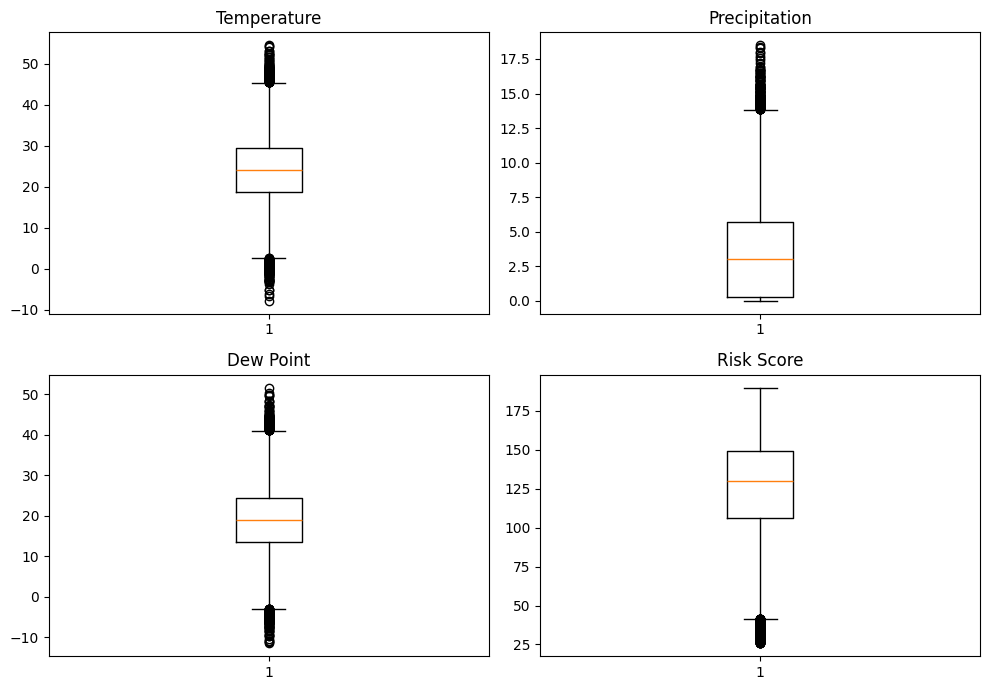

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.boxplot(df_clean["Temperature"])
plt.title("Temperature")

plt.subplot(2, 2, 2)
plt.boxplot(df_clean["Precipitation"])
plt.title("Precipitation")

plt.subplot(2, 2, 3)
plt.boxplot(df_clean["Dew_Point"])
plt.title("Dew Point")

plt.subplot(2, 2, 4)
plt.boxplot(df_clean["Risk_Score"])
plt.title("Risk Score")

plt.tight_layout()
plt.show()

In [ ]:
# Check consistency between dew point and temperature - dew point generally cannot exceed air temperature
dew_point_invalid = df_clean["Dew_Point"] > df_clean["Temperature"]
print("Dew point above temperature:", dew_point_invalid.sum())

Dew point above temperature: 0


The IQR method flagged unusual values in Temperature, Precipitation, Dew_Point and Risk_Score. These values were retained because exceeding an IQR boundary alone does not establish a data error. No dew-point values exceeded air temperature, providing an additional consistency check. No further records were removed.

In [ ]:
# Final dataset quality checks
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isna().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate Incident_IDs:", df_clean["Incident_ID"].duplicated().sum())

# Verify previously identified invalid ranges
print("Invalid latitude:", (~df_clean["Latitude"].between(-90, 90)).sum())
print("Invalid longitude:", (~df_clean["Longitude"].between(-180, 180)).sum())
print("Invalid humidity:", (~df_clean["Humidity"].between(0, 100)).sum())
print("Negative visibility:", (df_clean["Visibility"] < 0).sum())
print("Negative precipitation:", (df_clean["Precipitation"] < 0).sum())
print("Negative average speed:", (df_clean["Average_Speed"] < 0).sum())

Dataset shape: (49947, 72)
Missing values: 0
Duplicate rows: 0
Duplicate Incident_IDs: 0
Invalid latitude: 0
Invalid longitude: 0
Invalid humidity: 0
Negative visibility: 0
Negative precipitation: 0
Negative average speed: 0


## 1.3 Exploratory Data Analysis (EDA)


In [1]:
import pandas as pd

dataset_url = "https://raw.githubusercontent.com/zeemohamed7/ai-traffic-project/main/traffic_incidents_cleaned.csv"

df_eda = pd.read_csv(
    dataset_url,
    parse_dates=["Start_Time", "End_Time"],
    dtype={"Postal_Code": str}
)

### 1.3.1 Feature Distributions

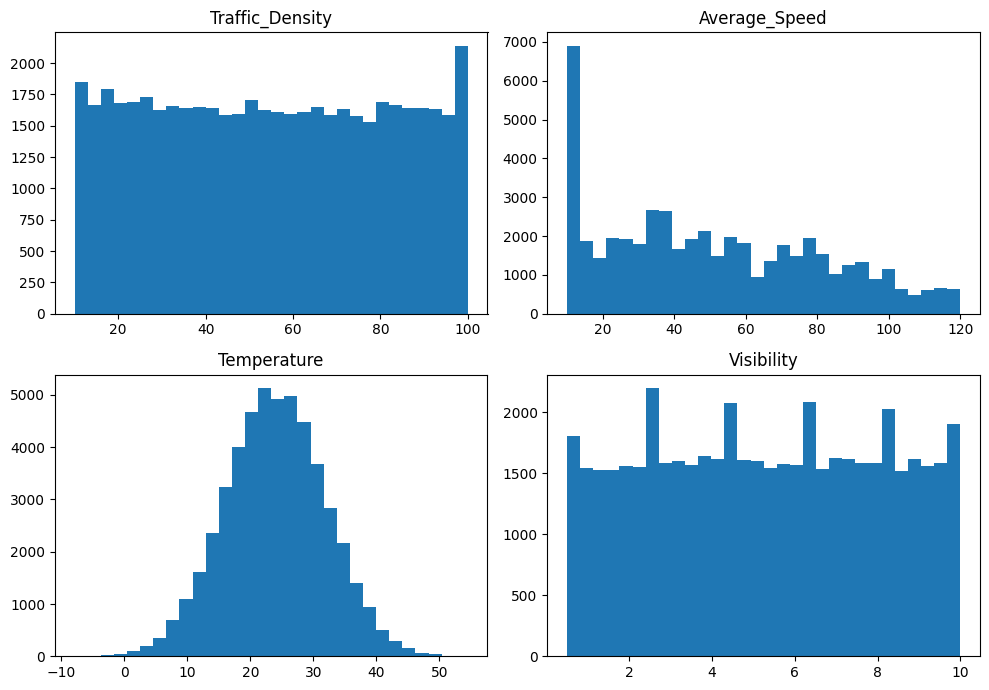

In [3]:
import matplotlib.pyplot as plt

columns = ["Traffic_Density", "Average_Speed", "Temperature", "Visibility"]

df_eda[columns].hist(bins=30, figsize=(10, 7), grid=False)

plt.tight_layout()
plt.show()

Traffic density and visibility are fairly evenly spread. Average speed has a large peak near 10 km/h, with fewer records at higher speeds. Most temperatures are around 20–30°C, with fewer very low or very high values.

### 1.3.2 Numerical Features and Severity

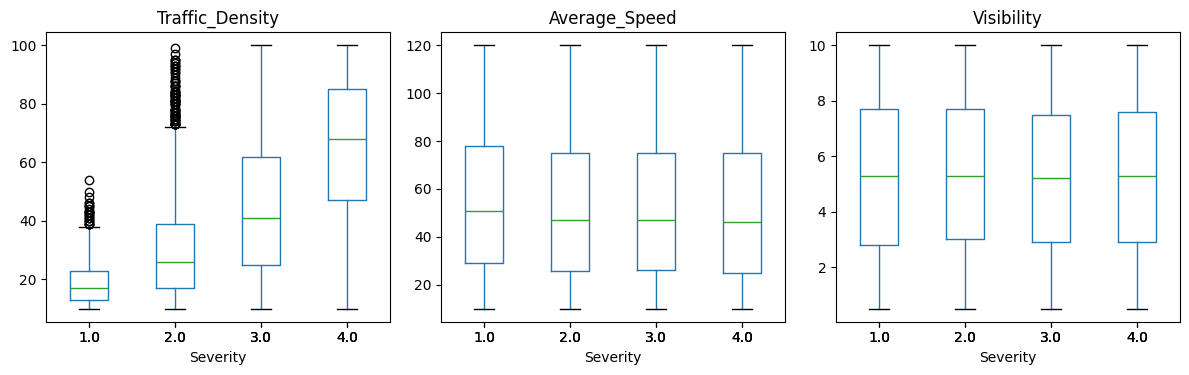

In [4]:
columns = ["Traffic_Density", "Average_Speed", "Visibility"]

df_eda.boxplot(
    column=columns,
    by="Severity",
    figsize=(12, 4),
    layout=(1, 3),
    sharey=False,
    grid=False
)

plt.suptitle("")
plt.tight_layout()
plt.show()

Traffic density is generally higher in the more severe incidents. Average speed is slightly higher for Severity 1, but the groups overlap considerably. Visibility looks similar across all four severity groups.

### 1.3.3 Road Type, Weather and Severity

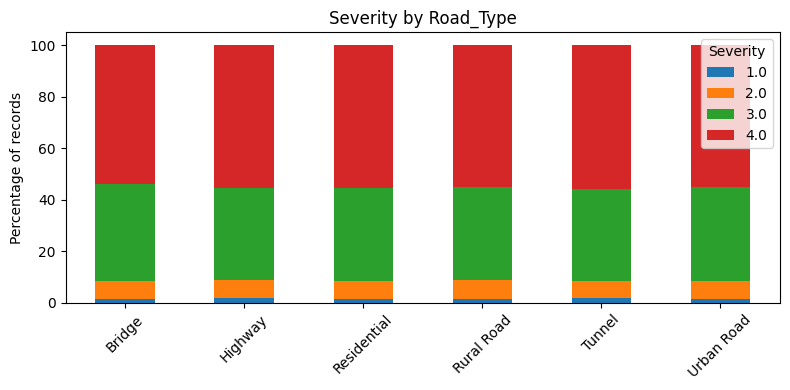

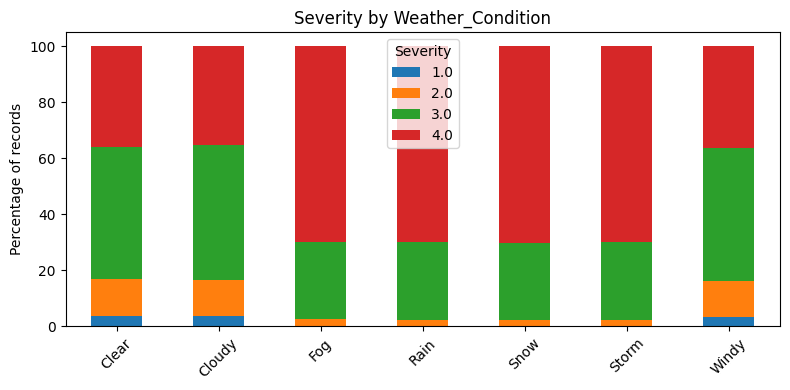

In [5]:
for col in ["Road_Type", "Weather_Condition"]:
    percentages = pd.crosstab(
        df_eda[col], df_eda["Severity"], normalize="index"
    ) * 100

    percentages.plot(kind="bar", stacked=True, figsize=(8, 4))

    plt.title(f"Severity by {col}")
    plt.ylabel("Percentage of records")
    plt.xlabel("")
    plt.xticks(rotation=45)
    plt.legend(title="Severity")
    plt.tight_layout()
    plt.show()

Severity proportions are similar across all road types. Severity 4 is the most common, followed by Severity 3, while Severities 1 and 2 make up much smaller shares. This chart shows no clear difference in severity between road types.

Fog, rain, snow and storm conditions have a larger share of Severity 4 incidents, at around 70%. Clear, cloudy and windy conditions have more Severity 3 incidents and larger shares of Severities 1 and 2. Weather shows a clearer relationship with severity than road type in this dataset.

### 1.3.4 EDA Summary
Traffic density was generally higher in more severe incidents. Fog, rain, snow and storms also had a higher share of Severity 4 incidents. Average speed, visibility and road type looked similar across severity groups. These patterns can help with feature selection, but do not prove cause and effect.

# 2. Feature Analysis and Selection

This section analyses the cleaned data for identifiers and target revealing columns, encodes categorical variables, and quantifies and plans for the Severity class imbalance.

## 2.1 Leakage Checks, Encoding and Imbalance

###  2.1.1 Loading the cleaned data

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataset_url = "https://raw.githubusercontent.com/zeemohamed7/ai-traffic-project/main/traffic_incidents_cleaned.csv"


df_fs = pd.read_csv(
    dataset_url,
    parse_dates=["Start_Time", "End_Time"],
    dtype={"Postal_Code": str}
)
df_fs["Severity"] = df_fs["Severity"].astype(int)
print(df_fs.shape)

(49947, 72)


### 2.1.2 Severity class distribution

Severity
1      781
2     3480
3    18138
4    27548
Name: count, dtype: int64
Severity
1    0.016
2    0.070
3    0.363
4    0.552
Name: proportion, dtype: float64


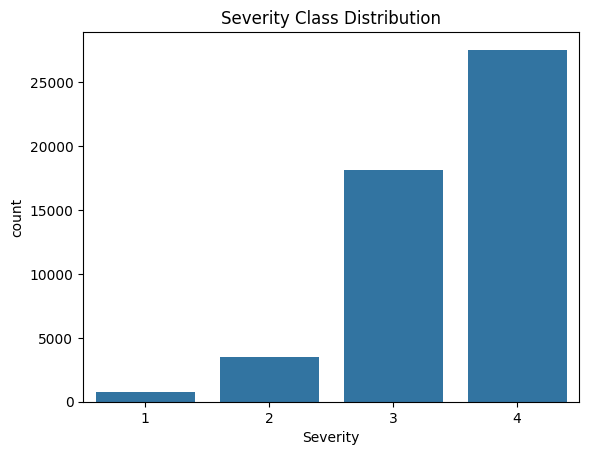

In [8]:
print(df_fs["Severity"].value_counts().sort_index())
print(df_fs["Severity"].value_counts(normalize=True).sort_index().round(3))

sns.countplot(x="Severity", data=df_fs)
plt.title("Severity Class Distribution")
plt.show()

### 2.1.3 Severity imbalance handling plan

Severity is imbalanced (Severity 4 = 55.2%, Severity 1= 1.6%), so accuracy alone is misleading, because a model that always predicts Severity 4 would score about 55%. Plan: 1. Use a stratified split, 2. handle imbalance on the training set only( class weights or SMOTE), never on the test set, and 3. evaluate with macro F1, precision, recall and confusion matrices

### 2.1.4 Leakage check

Findings: Risk_Score (37.8 to 147.3) and Emergency_Response_Time (8.3 to 27.6) rise steadily with Severity, so they are treated as target revealing and are removed. Travel_Time_Minutes, Travel_Category and Response_Team are only known after an incident and are also removed. Accident_History rises with severity (2.6 to 11.7). It would be known before an accident, so it has been kept, but flagged as possible leakage. Congestion_Index stays flat across Severity levels.

In [9]:
check= ["Risk_Score", "Travel_Time_Minutes", "Emergency_Response_Time", "Congestion_Index", "Accident_History"]
print(df_fs.groupby("Severity")[check].mean().round(2))

          Risk_Score  Travel_Time_Minutes  Emergency_Response_Time  \
Severity                                                             
1              37.78               182.31                     8.27   
2              72.47               181.46                    14.70   
3             107.78               183.33                    20.51   
4             147.31               182.36                    27.62   

          Congestion_Index  Accident_History  
Severity                                      
1                    50.06              2.60  
2                    51.01              5.48  
3                    50.75              8.26  
4                    50.45             11.73  


### 2.1.5 drop columns, separate target and encode categories

In [10]:
drop_cols = [
    "Incident_ID","Road_Name", "Postal_Code",
    "Start_Time", "End_Time", "Day", "Year","Weekday",
    "Travel_Time_Minutes", "Travel_Category",
    "Emergency_Response_Time", "Response_Team",
    "Risk_Score", "City", "District"
]

X = df_fs.drop(columns=drop_cols + ["Severity"])
y= df_fs["Severity"]
print(X.shape)

(49947, 56)


### 2.1.6 Encode categories as numbers

In [11]:
X= pd.get_dummies(X, drop_first=True, dtype=int)
print(X.shape)

(49947, 93)


### 2.1.7 Training and Test Split

We use 80% of the data for training and 20% for testing. Stratification keeps the severity proportions similar in both sets. Setting random_state=42 makes the split repeatable.

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X.shape)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(49947, 93)
(39957, 93)
(9990, 93)
(39957,)
(9990,)


In [13]:
print("Training:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting:")
print(y_test.value_counts(normalize=True).sort_index())

Training:
Severity
1    0.015642
2    0.069675
3    0.363140
4    0.551543
Name: proportion, dtype: float64

Testing:
Severity
1    0.015616
2    0.069670
3    0.363163
4    0.551552
Name: proportion, dtype: float64


The training and test sets have similar severity proportions: about 1.6% for Severity 1, 7.0% for Severity 2, 36.3% for Severity 3 and 55.2% for Severity 4. This confirms that the stratified split preserved the class distribution.